# Projekt

In [730]:
import pandas as pd
from matplotlib import pyplot as plt
from Distributions import BetaDistribution, NormalDistribution, BinDistribution
import numpy as np
import scipy as sp
import scipy.special as sps

In [731]:
Threshold = 6
df = pd.read_csv("ESS11e04_2-subset_filtered.csv")
trust = df["trstplt"]
income = df["hinctnta"]

## A2. Frekventistisk utgångspunkt

In [732]:
def generateVariables(trust,income, Threshold):
    xj = len(income.loc[(trust >= Threshold) & (income <= 3)])
    nj = len(income.loc[income <= 3])
    xk = len(income.loc[(trust >= Threshold) & (income >= 8)])
    nk = len(income.loc[income >= 8])
    return [xj,nj,xk,nk]

In [733]:
[xj,nj,xk,nk] = generateVariables(trust,income, Threshold)

thetaj = xj/nj
thetak = xk/nk

print('Uppgift A2\n')
print(f'Andelen positiva svar i låginkomstgruppen är {round(thetaj,3)}')
print(f'Andelen positiva svar i höginkomstgruppen är {round(thetak,3)}') 
print(f'Skillnaden i andelarna är {round(thetaj-thetak,3)}\n\n')

Uppgift A2

Andelen positiva svar i låginkomstgruppen är 0.194
Andelen positiva svar i höginkomstgruppen är 0.24
Skillnaden i andelarna är -0.046




## A3. Konjugerade aposteriorifördelningar

In [734]:
def A3_b(xj,nj,xk,nk):

    Betaj = BetaDistribution(1+xj,1+nj-xj,10000).generateBetaDistribution() ## E is xj/nj
    Betak = BetaDistribution(1+xk,1+nk-xk,10000).generateBetaDistribution()

    Delta = Betaj-Betak
    negDelta = Delta[Delta <= 0]

    bayesDecision = len(negDelta)  / len(Delta)

    print(f'P(Delta>0) = {bayesDecision}')

    # plt.hist(Delta, density=True, bins = 50)
    # plt.show()

    if (bayesDecision < 0.5):
        return ['a1', Delta,Betaj]
    elif (bayesDecision > 0.5):
        return ['a0', Delta,Betaj]
    else:
        return ['Expected loss is equal', Delta,Betaj]

P(Delta>0) = 0.9478
Uppgift A3

Bayesbeslutet väljer Thetaj>Thetak: a0




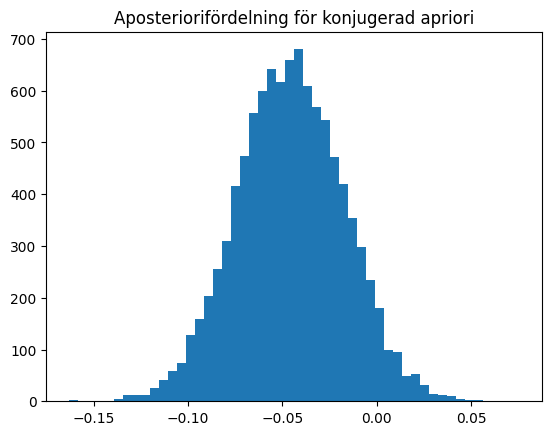

In [735]:
[decision, DeltaConj,Betaj] = A3_b(xj,nj,xk,nk)
print('Uppgift A3\n')
print(f'Bayesbeslutet väljer Thetaj>Thetak: {decision}\n\n')
plt.figure()
plt.title('Aposteriorifördelning för konjugerad apriori')
plt.hist(DeltaConj, bins=50)
plt.show()

## A4. En annan apriorifördelning

In [736]:
def A4_a(xj,xk,nj,nk): ## A4.a) calculation of parameters for prior (logit-normal)

    sigmaSquare = 0.1
    n = 100 ## megaslow be careful
    iter = 10000
    Theta = np.linspace(-10,10,iter)

    expectedGuessJ = 0.19
    expectedGuessK = 0.24

    for i in range(iter):
        Normal = NormalDistribution(Theta[i],sigmaSquare,n).generateNormalDistribution()
        logitNormal = 1/(1+np.exp(-Normal))
        mean = np.mean(logitNormal)
        # print(mean)
        if mean < expectedGuessJ+0.01 and mean > expectedGuessJ-0.01:
            mu_j = Theta[i]
        if mean < expectedGuessK+0.01 and mean > expectedGuessK -0.01:
            mu_k = Theta[i]

    Xj = NormalDistribution(mu_j,sigmaSquare, n).generateNormalDistribution()
    Xk = NormalDistribution(mu_k, sigmaSquare, n).generateNormalDistribution()

    Thetaj = 1/(1+np.exp(-Xj))
    Thetak = 1/(1+np.exp(-Xk))

    ## prior predictives

    rng = np.random.default_rng()

    PriorPredj = np.zeros(n)
    PriorPredk = np.zeros(n)


    for i in range(len(Thetaj)):

        binJ = BinDistribution(nj,Thetaj[i],n).generateBinDistribution()
        binK = BinDistribution(nk,Thetak[i],n).generateBinDistribution()

        PriorPredj[i] = rng.choice(binJ)
        PriorPredk[i] = rng.choice(binK)


    ## Plots of prior predictive vs observed data, use to determine prior parameters
    # plt.figure()
    # plt.hist(PriorPredj,bins = 25, label= "Prior Predictive for j")
    # plt.axvline(xj, color = "green", label = "Observed xj")
    # plt.legend()
    # plt.figure()
    # plt.hist(PriorPredk, bins = 25, label="Prior Predictive for k")
    # plt.axvline(xk, color = "green", label="Observed xk")
    # plt.legend()
    # plt.show()

    return [mu_j, mu_k, sigmaSquare]

In [737]:
def A4_b(xj, xk , nj, nk, mu_j, mu_k,sigmaSquare): ## A4.b) simulation of Posterior

    n = 10000

    Logmj = sp.stats.binom.logpmf(xj, nj, xj / nj)
    Logmk = sp.stats.binom.logpmf(xk, nk, xk / nk)

    PosteriorJ = []
    PosteriorK = []

    max_iter = 1000000
    iter = 0 

    while (len(PosteriorJ) < n) and (iter < max_iter):
        Xj = sp.stats.norm.rvs(loc=mu_j, scale=np.sqrt(sigmaSquare))
        Thetaj = sp.special.expit(Xj) 
        Uj = sp.stats.uniform.rvs()
        if (np.log(Uj)) < sp.stats.binom.logpmf(xj,nj,Thetaj) - Logmj:
            PosteriorJ.append(Thetaj)
        iter+= 1

    if (iter == max_iter):
        print('Rejection sampling did not converge for ThetaJ')

    iter = 0

    while (len(PosteriorK) < n) and (iter < max_iter):
        Xk = sp.stats.norm.rvs(loc=mu_k, scale=np.sqrt(sigmaSquare))
        Thetak = sp.special.expit(Xk)
        Uk = sp.stats.uniform.rvs()
        if (np.log(Uk)) < sp.stats.binom.logpmf(xk,nk,Thetak) - Logmk:
            PosteriorK.append(Thetak)
        iter += 1

    if (iter == max_iter):
            print('Rejection sampling did not converge for ThetaK')

    PosteriorJ = np.array(PosteriorJ)
    PosteriorK = np.array(PosteriorK)


    if (len(PosteriorK) != len(PosteriorK)):
        print('Lengths did not match')
        return
    else:
        return [PosteriorJ, PosteriorK]

In [738]:
def A4_c(trust, income):
    sampleTrust = trust.sample(n=10, random_state=42)
    sampleIncome = income.sample(n=10, random_state=42)
    [xj,nj,xk,nk] = generateVariables(sampleTrust, sampleIncome, Threshold=6)
    [_, DeltaConj, Betaj] = A3_b(xj,nj,xk,nk)
    [mu_j, mu_k, sigmaSquare] = A4_a(xj,xk,nj,nk)
    [PosteriorJ,PosteriorK] = A4_b(xj, xk, nj, nk, mu_j, mu_k, sigmaSquare)
    plt.title('Jämförelse mellan Aposteriori, 10 respondenter')
    plt.hist(DeltaConj, bins = 10, density = True, alpha = 0.6, label='Aposteriori med konjugerad apriori')
    plt.hist(PosteriorJ-PosteriorK, bins = 10, density = True, alpha = 0.6, label='Aposteriori med logit-normal apriori')
    plt.legend().set_draggable(True)
    plt.show()

In [739]:
[mu_j, mu_k, sigmaSquare] = A4_a(xj,xk,nj,nk) # very slow, data printed below

## Results of A4_a
# mu_j = -1.6551
# mu_k = -1.0011
# sigmaSquare = 0.1

In [740]:
[PosteriorJ,PosteriorK] = A4_b(xj, xk, nj, nk, mu_j, mu_k, sigmaSquare)
Delta2 = PosteriorJ-PosteriorK
print('Uppgift A4\n')
print(f'Aposterioriväntevärde för Delta är {np.mean(Delta2)}')
se = Delta2.std(ddof=1) / np.sqrt(len(Delta2)) ## std(ddof=1) ger s^2 = 1/(n-1) Sum (x_i - \bar x)^2
print(f'Montecarlo-medelfelet för förkastelsemetoden är {se}')

print(f'Stickprovsstandardavvikelse: {Delta2.std(ddof=1)}')


Uppgift A4

Aposterioriväntevärde för Delta är -0.045865805278417875
Montecarlo-medelfelet för förkastelsemetoden är 0.00026418169864755826
Stickprovsstandardavvikelse: 0.026418169864755828


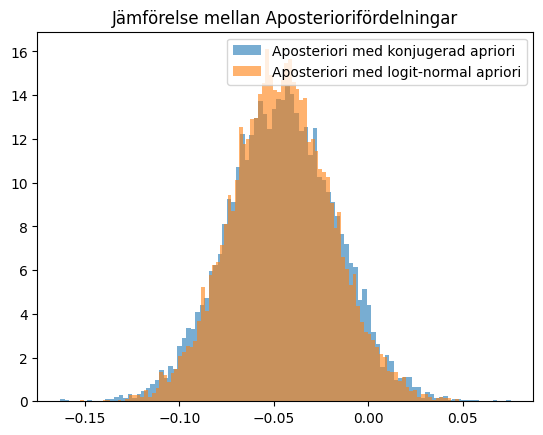

In [741]:
plt.title('Jämförelse mellan Aposteriorifördelningar')
plt.hist(DeltaConj, bins = 100, density = True, alpha = 0.6, label='Aposteriori med konjugerad apriori')
plt.hist(Delta2, bins = 100, density = True, alpha = 0.6, label='Aposteriori med logit-normal apriori')
plt.legend().set_draggable(True)
plt.show()

P(Delta>0) = 0.3647


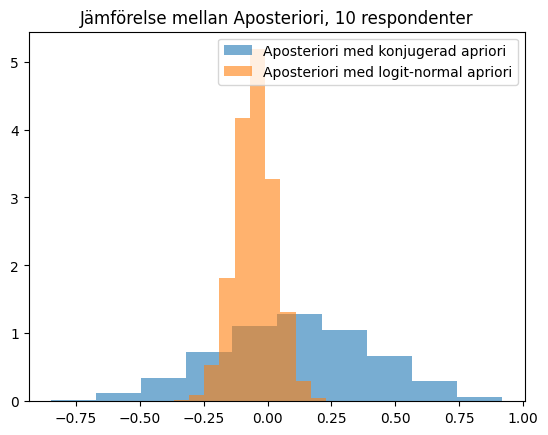

In [742]:
A4_c(trust,income)

## A5. Den hierarkiska modellen

In [743]:
def A5_a(trust, income, Threshold):
    x1 = len(income.loc[(trust >= Threshold) & (income <= 3)])
    n1 = len(income.loc[income <= 3])
    x2 = len(income.loc[(trust >= Threshold) & (income == 4)])
    n2 = len(income.loc[income == 4])
    x3 = len(income.loc[(trust >= Threshold) & (income == 5)])
    n3 = len(income.loc[income == 5])
    x4 = len(income.loc[(trust >= Threshold) & (income == 6)])
    n4 = len(income.loc[income == 6])
    x5 = len(income.loc[(trust >= Threshold) & (income == 7)])
    n5 = len(income.loc[income == 7])
    x6 = len(income.loc[(trust >= Threshold) & (income >= 8)])
    n6 = len(income.loc[income >= 8])

    X = [x1, x2, x3, x4, x5, x6]
    N = [n1, n2, n3, n4, n5, n6]

    return [X,N]

In [744]:
def logpdf(alpha,beta,X,N):
    term1 = (-5/2)*np.log(alpha+beta)
    term2 = len(X)*(sps.loggamma(alpha+beta)-sps.loggamma(alpha)-sps.loggamma(beta))
    term3 = 0
    for i in range(len(X)):
        num = sps.loggamma(X[i]+alpha)+sps.loggamma(beta+N[i]-X[i])
        den = sps.loggamma(alpha+beta+N[i])
        term3 += num - den
    return term1+term2+term3

In [745]:
def invTransformation(gamma,chi):
    alpha = np.exp(gamma+chi) / (1+np.exp(gamma))
    beta =  np.exp(chi) / (1+np.exp(gamma))
    return [alpha,beta]

def Transformation(alpha,beta):
    gamma = np.log(alpha/beta)
    chi = np.log(alpha+beta)
    return [gamma,chi]

def transformedLogPdf(gamma,chi,X,N):
    [alpha,beta] = invTransformation(gamma,chi)
    return logpdf(alpha,beta,X,N)+np.log(alpha)+np.log(beta)

In [746]:
def Metropolis(X,N, iter):
    rng = np.random.default_rng(1223)
    step = 0.5
    Starts = [[1,2],[29,50],[10,15],[6,14]]
    transformedStarts = [Transformation(start[0],start[1]) for start in Starts]    
    chains = []
    for start in transformedStarts:
        chain = np.zeros((iter,2))
        current = np.array(start)
        logpdfCurrent = transformedLogPdf(current[0],current[1],X,N)

        accepted = 0
        for i in range(iter):
            prop = current+step*rng.standard_normal(2)
            logpdfProp = transformedLogPdf(prop[0],prop[1],X,N)

            if np.log(rng.uniform()) < logpdfProp - logpdfCurrent:
                current = prop
                logpdfCurrent = logpdfProp
                accepted+=1

            chain[i] = current

        chains.append(chain)

    return chains

In [747]:
def A5_b(X,N,endpoint,n):

    Alpha = np.linspace(0.001,endpoint/2,n)
    Beta = np.linspace(0.001,endpoint,n)
    f = np.zeros((n,n))

    for i in range(n):
        beta = Beta[i]
        for j in range(n):
            alpha = Alpha[j] 
            f[i][j] = logpdf(alpha,beta,X,N)

    f = f - f.max()
    posDensity =  np.exp(f)

    iter = 1000000
    cutoff = round(iter/2)
    
    chains = Metropolis(X,N,iter)

    [A, B] = invTransformation(chains[0][cutoff:, 0], chains[0][cutoff:, 1])
    kappa = A + B

    ## Generera Theta_j

    Theta = np.zeros((len(X),len(A)))
    rng = np.random.default_rng()
    for j in range(len(X)):
        for i in range(len(A)):
            Theta[j,i] = rng.beta(A[i]+X[j],B[i]+N[j]-X[j])


    return [A,B,Alpha, Beta, posDensity, iter, chains, Theta]



In [748]:
def A5_c(X,N,Theta):
    X = np.array(X)
    N = np.array(N)
    thetaHats = X / N

    m1 = sum(thetaHats) / len(thetaHats)
    m2 = sum(thetaHats**2) / len(thetaHats)

    alpha = (m1*(m2-m1)) / (m1**2-m2)
    beta = ((1-m1)*(m2-m1)) / (m1**2-m2)

    PosteriorMeansEmp = (alpha+X) / (alpha+beta+N)
    PosteriorStdEmp = np.sqrt(((alpha+X)*(beta+N-X))/((alpha+beta+N)**2*(alpha+beta+N+1)))
    PosteriorMeansMetro = np.mean(Theta, axis=1)
    PosteriorStdMetro = np.std(Theta,axis=1)

    EmpiricalThetaj = sp.stats.beta.rvs(alpha+X[0],beta+N[0]-X[0],size=10000)
  

    print(len(PosteriorMeansEmp))
    return [PosteriorMeansEmp, PosteriorStdEmp, PosteriorMeansMetro, PosteriorStdMetro, EmpiricalThetaj]

In [749]:
[X,N] = A5_a(trust, income, Threshold)
[A,B,Alpha, Beta, Density, iter, chains, Theta] = A5_b(X,N,endpoint = 200, n = 1000)



Konturplott av täthetsfunktionen

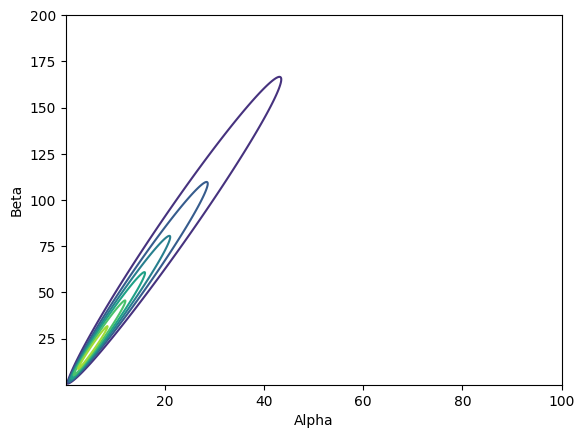

In [750]:
plt.contour(Alpha,Beta, Density)
plt.xlabel("Alpha")
plt.ylabel("Beta")
plt.show()

Plott av Markovkedjor i transformerade koordinater

C:\Users\Admin\AppData\Local\Temp\ipykernel_13904\1261337068.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


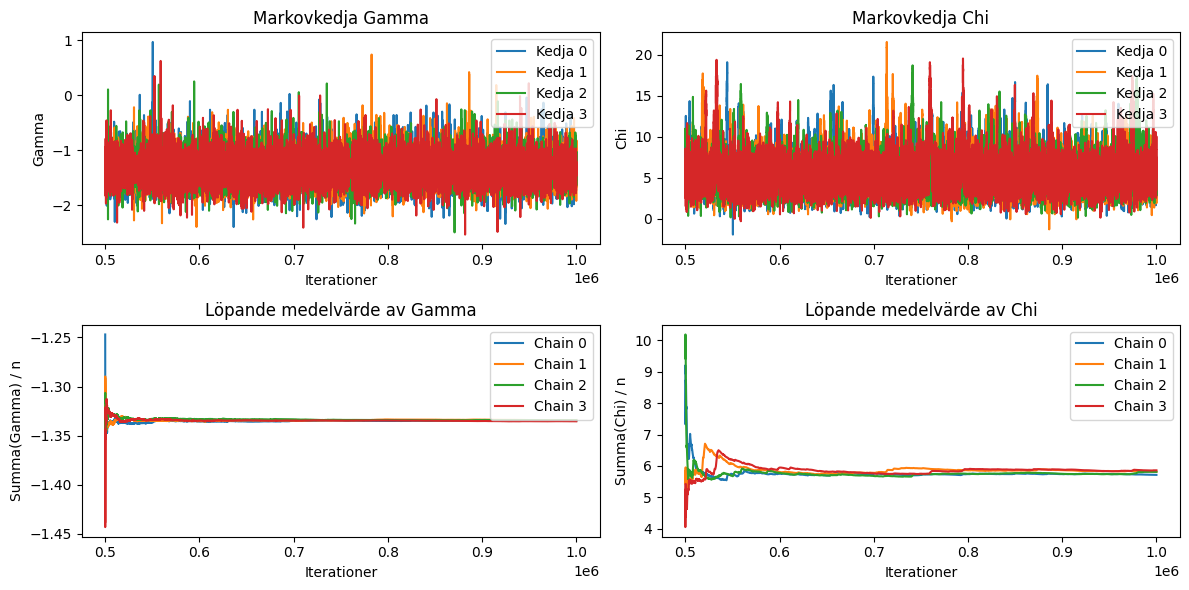

In [751]:
cutoff = round(iter/2)


Arranged = np.arange(1,cutoff+1)
Iters = np.arange(cutoff,iter)

plt.figure(figsize=(12,6))
plt.subplot(2,2,1)
plt.title('Markovkedja Gamma')
for i in range(4):
    chain = chains[i]
    plt.plot(Iters,chain[cutoff:,0], label= f'Kedja {i}')
plt.xlabel('Iterationer')
plt.ylabel('Gamma')
plt.legend()

plt.subplot(2,2,2)
plt.title("Markovkedja Chi")
for i in range(4): 
    chain  = chains[i]
    plt.plot(Iters,chain[cutoff:,1], label=f'Kedja {i}')
plt.xlabel('Iterationer')
plt.ylabel('Chi')
plt.legend()

plt.subplot(2,2,3)
plt.title('Löpande medelvärde av Gamma')
for i in range(4):
    chain = chains[i]
    plt.plot(Iters,np.cumsum(chain[cutoff:,0]) / Arranged, label=f'Chain {i}')
plt.xlabel('Iterationer')
plt.ylabel('Summa(Gamma) / n')
plt.legend()

plt.subplot(2,2,4)
plt.title('Löpande medelvärde av Chi')
for i in range(4):
    chain = chains[i]
    plt.plot(Iters,np.cumsum(chain[cutoff:,1]) / Arranged, label=f'Chain {i}')
plt.xlabel('Iterationer')
plt.ylabel('Summa(Chi) / n')
plt.legend()

plt.tight_layout()
plt.show()

Plott av Theta för alla grupper

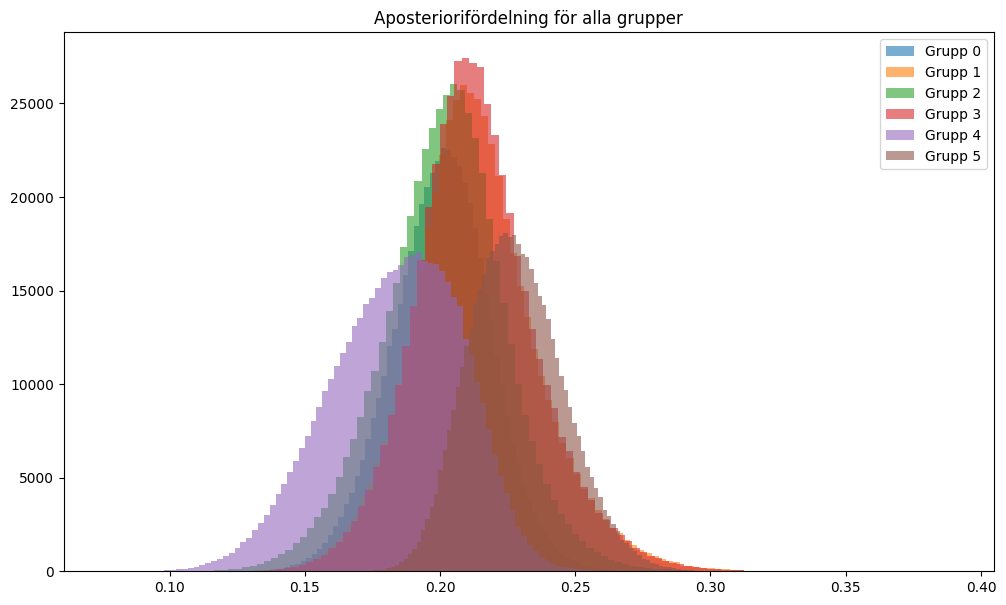

In [752]:
plt.figure(figsize=(12,7))
plt.title('Aposteriorifördelning för alla grupper')
for j in range(len(Theta)):
    plt.hist(Theta[j], bins=100, alpha=0.6, label = f'Grupp {j}')
plt.legend()
plt.show()

Jämförelse med Empirisk Bayes

6


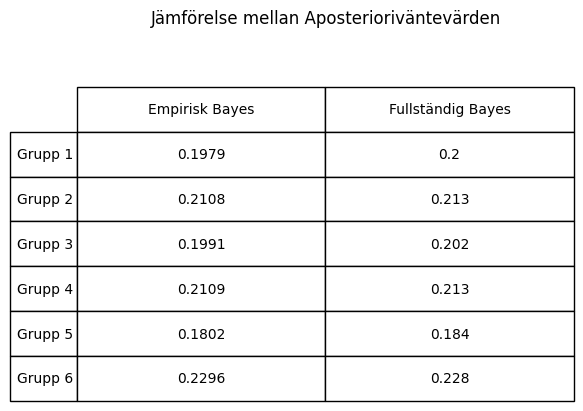

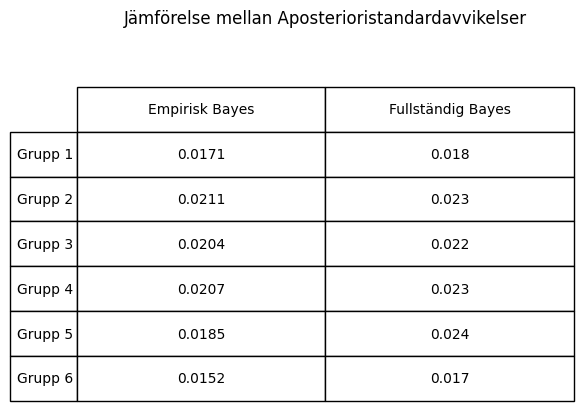

In [753]:
[EmpMean, EmpStd, MetroMean, MetroStd,EmpiricalThetaj] = A5_c(X,N,Theta)


fig1,ax1 = plt.subplots()
ax1.axis("off")
ax1.set_title('Jämförelse mellan Aposterioriväntevärden')
ax1.table(
    cellText=[[round(EmpMean[i],4), round(MetroMean[i],3)] for i in range(len(EmpMean))],
    colLabels=['Empirisk Bayes', 'Fullständig Bayes'],
    rowLabels=[f'Grupp {i+1}' for i in range(len(EmpMean))],
    loc='center',
    cellLoc='center',
    bbox = [0,0,1,0.85]
)
fig2,ax2 = plt.subplots()
ax2.axis("off")
ax2.set_title('Jämförelse mellan Aposterioristandardavvikelser')
ax2.table(
    cellText=[[round(EmpStd[i],4), round(MetroStd[i],3)] for i in range(len(EmpMean))],
    colLabels=['Empirisk Bayes', 'Fullständig Bayes'],
    rowLabels=[f'Grupp {i+1}' for i in range(len(EmpStd))],
    loc='center',
    cellLoc='center',
    bbox = [0,0,1,0.85]
)
plt.show()

## A6. Skillnaden i den hierarkiska modellen

In [754]:
def A6_a(Theta):
    Delta = Theta[0]-Theta[5]
    PosteriorMean = np.mean(Delta)
    PosteriorStdDev = np.std(Delta)
    posDelta = Delta[Delta >= 0]
    diffProb = len(posDelta)  / len(Delta)
    return [Delta,PosteriorMean,PosteriorStdDev,diffProb]

In [755]:
def A6_b(Theta):
    Delta = Theta[5]-Theta[0]
    varDelta = (np.std(Delta))**2
    varThetaJ = (np.std(Theta[0]))**2
    varThetaK = (np.std(Theta[5]))**2
    covar = np.cov(Theta[0],Theta[5])
    corrCoef = np.corrcoef(Theta[0],Theta[5])[0,1]
    return [varDelta, varThetaJ+varThetaK,covar,corrCoef]

In [756]:
def A6_c(X,N):
    x = sum(X)
    n = sum(N)
    Theta = BetaDistribution(1+x,1+n-x,10000).generateBetaDistribution()
    return Theta

In [757]:
def A6_d(A,B):
    rng = np.random.default_rng(101)
    Theta1 = rng.beta(A,B)
    Theta2 = rng.beta(A,B)
    DeltaNew = Theta1-Theta2
    return DeltaNew

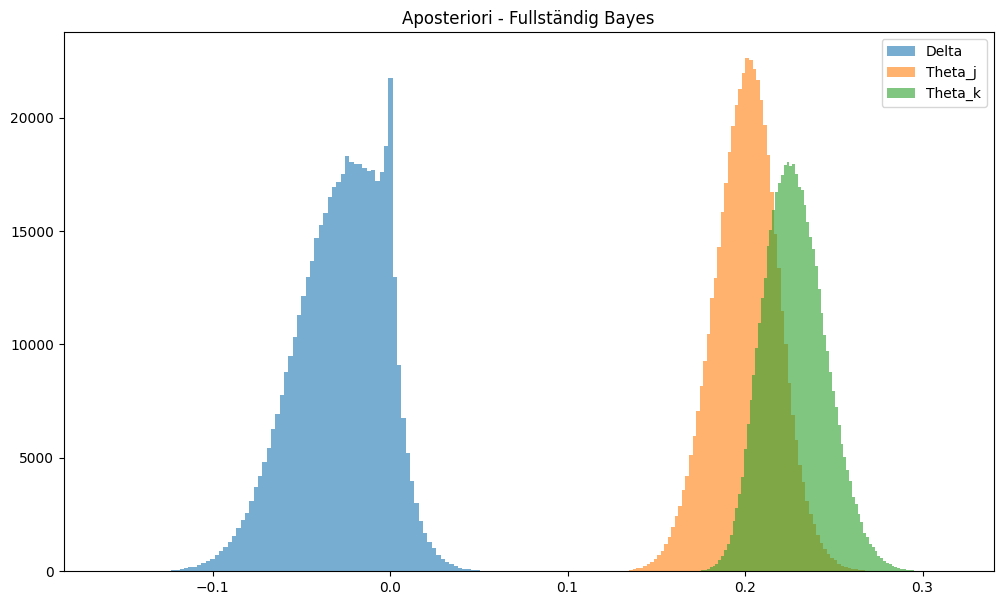

Aposterioriväntevärde: -0.027725860611393705
Aposterioristandardavvikelse: 0.025109839963796683
P(Theta_j>Theta_k) = 0.125076
Varians för Delta: 0.000630504063007481
Varians för Thetaj+Thetak: 0.0006345976610841483
Covarians mellan Thetaj,Thetak: [[3.29227292e-04 2.04680313e-06]
 [2.04680313e-06 3.05371638e-04]]
Korelationskoefficient: 0.006455261029932309


In [758]:
[Delta, PosteriorMean, PosteriorStdDev, diffProb] = A6_a(Theta)
[varDelta,varSum,covar,corrCoef] = A6_b(Theta)
plt.figure(figsize=(12,7))
plt.title('Aposteriori - Fullständig Bayes')
plt.hist(Delta,alpha=0.6, bins=100, label='Delta')
plt.hist(Theta[0], alpha=0.6,bins = 100, label='Theta_j')
plt.hist(Theta[5], alpha=0.6,bins = 100, label='Theta_k')
plt.legend()
plt.show()
print(f'Aposterioriväntevärde: {PosteriorMean}')
print(f'Aposterioristandardavvikelse: {PosteriorStdDev}')
print(f'P(Theta_j>Theta_k) = {diffProb}')
print(f'Varians för Delta: {varDelta}')
print(f'Varians för Thetaj+Thetak: {varSum}')
print(f'Covarians mellan Thetaj,Thetak: {covar}')
print(f'Korelationskoefficient: {corrCoef}')


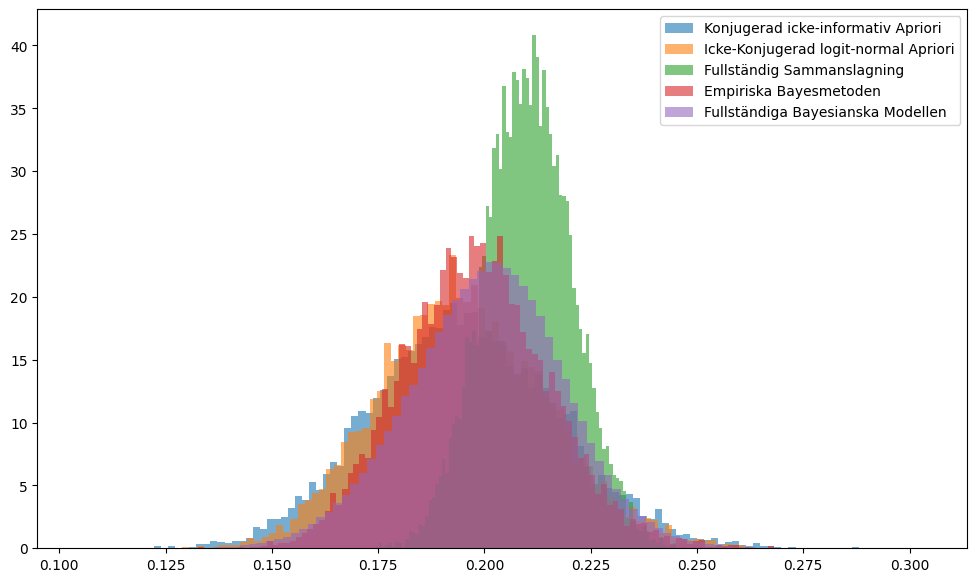

[np.float64(0.19538102847063113), np.float64(0.19507873050368707), np.float64(0.21032548059519096), np.float64(0.1978081942848847), np.float64(0.20045604896331898)]


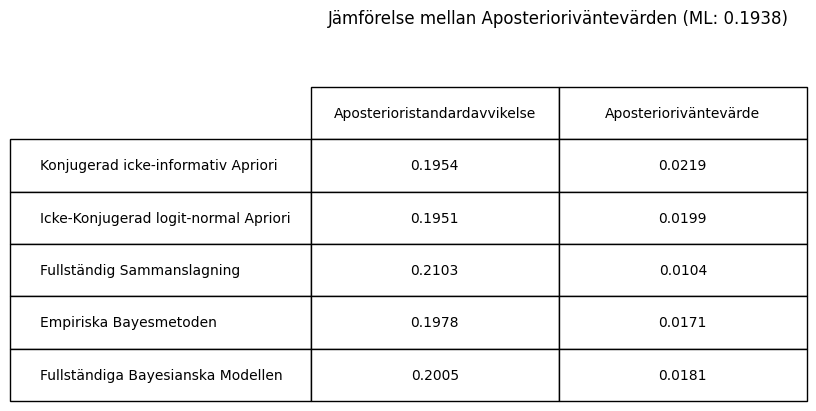

In [759]:
pooledTheta = A6_c(X,N)
Thetas = [Betaj,PosteriorJ,pooledTheta,EmpiricalThetaj,Theta[0]]
plt.figure(figsize=(12,7))
plt.hist(Thetas[0],bins=100,density=True,alpha=0.6,label='Konjugerad icke-informativ Apriori')
plt.hist(Thetas[1],bins=100,density=True,alpha=0.6,label='Icke-Konjugerad logit-normal Apriori')
plt.hist(Thetas[2],bins=100,density=True,alpha=0.6,label='Fullständig Sammanslagning')
plt.hist(Thetas[3],bins=100,density=True,alpha=0.6,label='Empiriska Bayesmetoden')
plt.hist(Thetas[4],bins=100,density=True,alpha=0.6,label='Fullständiga Bayesianska Modellen')
plt.legend()
plt.show()

Means = [np.mean(Theta) for Theta in Thetas]
Std_Devs = [np.std(Theta) for Theta in Thetas]
print(Means)

fig1,ax1 = plt.subplots()
ax1.axis("off")
ax1.set_title(f'Jämförelse mellan Aposterioriväntevärden (ML: {round(thetaj,4)})')
ax1.table(
    cellText=[[round(Means[i],4), round(Std_Devs[i],4)] for i in range(len(Means))],
    colLabels=['Aposterioristandardavvikelse','Aposterioriväntevärde'],
    rowLabels=['Konjugerad icke-informativ Apriori',
               'Icke-Konjugerad logit-normal Apriori',
               'Fullständig Sammanslagning',
               'Empiriska Bayesmetoden', 
               'Fullständiga Bayesianska Modellen'],
    loc='center',
    cellLoc='center',
    bbox = [0,0,1,0.85]
)

plt.show()

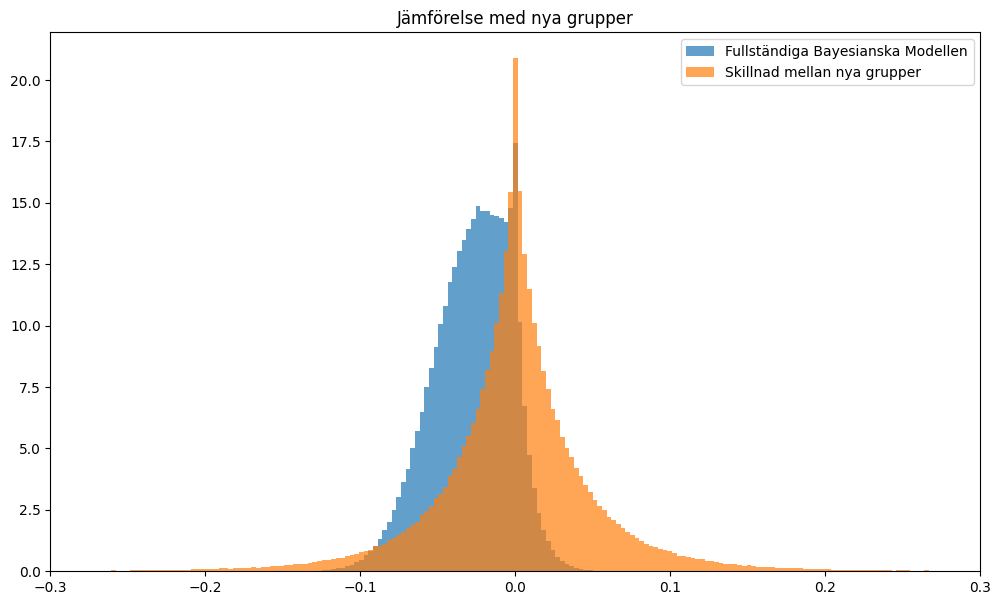

In [760]:
DeltaNew = A6_d(A,B)
bins = np.linspace(-0.3, 0.3, 200)
plt.figure(figsize=(12,7))
plt.title('Jämförelse med nya grupper')
plt.hist(Theta[0]-Theta[5],bins=bins,density=True,alpha=0.7,label='Fullständiga Bayesianska Modellen')
plt.hist(DeltaNew,bins=bins, density=True, alpha=0.7,label='Skillnad mellan nya grupper')
plt.xlim(-0.3, 0.3)
plt.legend()
plt.show()


## A7. Selektion

In [761]:
def A7_a(X,N,Theta):
    X = np.array(X)
    N = np.array(N)
    Thetahat = X / N
    indexT = np.argmax(Thetahat)
    indexB = np.argmin(Thetahat)

    print(indexT)
    print(indexB)

    xT = X[indexT]
    nT = N[indexT]

    xB = X[indexB]
    nB = N[indexB]

    thetaConjT = BetaDistribution(1+xT,1+nT-xT,10000).generateBetaDistribution() 
    thetaConjB = BetaDistribution(1+xB,1+nB-xB,10000).generateBetaDistribution()
    DeltaConj = thetaConjT-thetaConjB

    thetaHierT = Theta[indexT]
    thetaHierB = Theta[indexB]
    DeltaHier = thetaHierT-thetaHierB

    posDeltaConj = DeltaConj[DeltaConj >= 0]
    posProbConj = len(posDeltaConj)  / len(DeltaConj)

    posDeltaHier = DeltaHier[DeltaHier >= 0]
    posProbHier = len(posDeltaHier) / len(DeltaHier)



    return [posProbConj,posProbHier]


In [762]:
def A7_b(X,N,Theta):
    ## used indices T=5,B=4
    X = np.array(X)
    N = np.array(N)

    DeltaHier = Theta[5]-Theta[4]


    ThetaConjList = []
    for i in range(len(X)):
        ThetaConjList.append(BetaDistribution(1+X[i],1+N[i]-X[i],10000).generateBetaDistribution())

    DeltaConj = ThetaConjList[5]-ThetaConjList[4]
    
    pairs = []

    for i in range(len(X)):
        for j in range(len(X)):
            pairs.append([i,j])

    diffDeltasConj = []
    diffDeltasHier = []

   

    for i in range(len(pairs)):
        idx1 = pairs[i][0]
        idx2 = pairs[i][1]

        diffDeltasConj.append(DeltaConj-(ThetaConjList[idx1]-ThetaConjList[idx2]))
        diffDeltasHier.append(DeltaHier-(Theta[idx1]-Theta[idx2]))
    print(len(diffDeltasConj))
    print(len(diffDeltasConj[1]))

    countConj = 0
    countHier = 0

    for i in range(len(diffDeltasConj[1])):
        diffsConj = []
        for j in range(len(diffDeltasConj)):
            if diffDeltasConj[j][i]>=0:
                diffsConj.append(diffDeltasConj[j][i])
        if len(diffsConj) == len(diffDeltasConj):
            countConj += 1
    for i in range(len(diffDeltasHier[1])):
        diffsHier = []
        for j in range(len(diffDeltasHier)):
            if diffDeltasHier[j][i]>=0:
                diffsHier.append(diffDeltasHier[j][i])
        if len(diffsHier) == len(diffDeltasHier):
            countHier+=1


        ## Vi lägger till 1 endast skillnaden är positivt för varje grupp för given index

    probPosConj = countConj / len(DeltaConj)
    probPosHier = countHier / len(DeltaHier)

    return [probPosConj,probPosHier]

        


    

    return 

In [763]:
[posProbConj,posProbHier] = A7_a(X,N,Theta)
print(f'P(Thetat>Thetab) för konjugerad modell: {posProbConj}')
print(f'P(Thetat>Thetab) för hierarkisk modell: {posProbHier}')
A7_b(X,N,Theta)

5
4
P(Thetat>Thetab) för konjugerad modell: 0.9943
P(Thetat>Thetab) för hierarkisk modell: 0.93418
36
10000


[0.3105, 0.258726]

## A8. Intervall 

In [764]:
def A8_a(X,N,DeltaHier):
    
    [WaldIntlower,WaldIntupper] = walderInterval(X[0],N[0],X[5],N[5])
    [AgrCaffoIntlower,AgrCaffoIntupper] = walderInterval(X[0]+1,N[0]+2,X[5]+1,N[5]+2)

    ThetaConjJ = BetaDistribution(1+X[0],1+N[0]-X[0],10000).generateBetaDistribution() ## E is xj/nj
    ThetaConjK = BetaDistribution(1+X[0],1+N[0]-X[0],10000).generateBetaDistribution()
    DeltaConj = ThetaConjJ - ThetaConjK
    lowerConj, upperConj = np.quantile(DeltaConj, [0.025, 0.975])


    lowerHier, upperHier = np.quantile(DeltaHier, [0.025,0.975])

    lowers = [WaldIntlower,AgrCaffoIntlower,lowerConj,lowerHier]
    uppers = [WaldIntupper,AgrCaffoIntupper,upperConj,upperHier]

    return [lowers,uppers]



In [765]:
def walderInterval(xj,nj,xk,nk):
    thetaj = xj/nj
    thetak = xk/nk
    lambda_quantile = sp.stats.norm.ppf(1-0.025)
    delta = thetaj-thetak
    val1 = (thetaj*(1-thetaj))/(nj)
    val2 = (thetak*(1-thetak))/(nk)
    val3=lambda_quantile*np.sqrt(val1+val2)
    return [delta-val3, delta+val3]

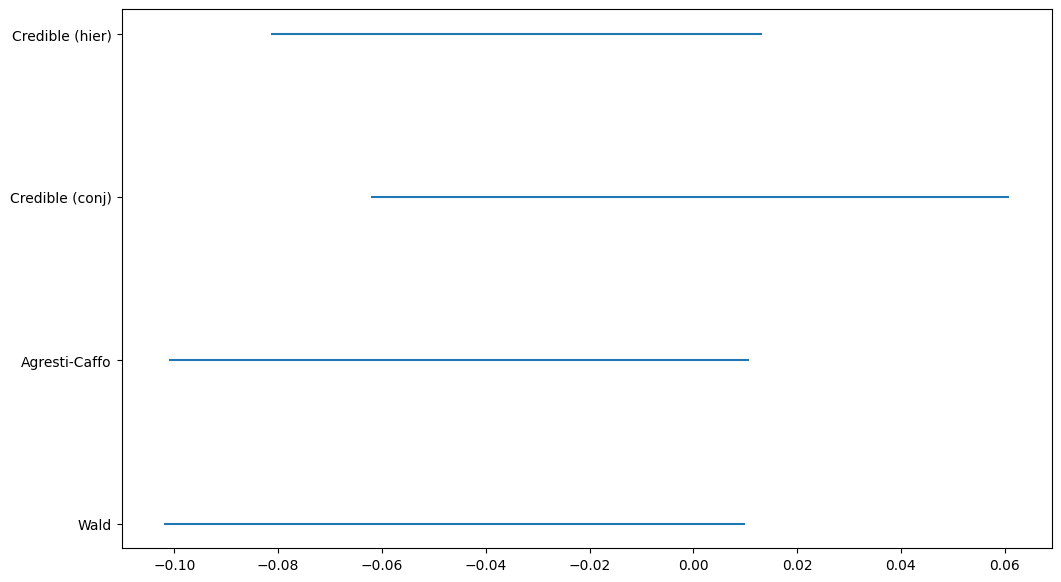

In [766]:
[lowers,uppers] = A8_a(X,N,Delta)

plt.figure(figsize=(12,7))
plt.hlines([0,1,2,3],lowers,uppers)
plt.yticks([0,1,2,3],['Wald','Agresti-Caffo', 'Credible (conj)', 'Credible (hier)'])
plt.show()
